---
embed-resources: True
format:
    html:
        page-layout: full
        fontsize: 18px
        css: print.css
        code-overflow: wrap

title: 'Parte II | Markov y Monte Carlo'
author: 'Lorenzo Marquesini'
execute:
    echo: false
warning: False
toc: False
---

## Pregunta y alcance

La Parte I produjo dos planes semanales: el **nominal**, de mínimo costo para la semana típica, y el de **resguardo**, calculado con una demanda de diseño 5 % mayor. Este notebook responde la segunda mitad de la pregunta central: **¿qué tan confiable sigue siendo cada plan cuando demanda y capacidad cambian con persistencia temporal?**

1. Estima una cadena de Markov de regímenes semanales (Normal, Pico, Disrupción) y analiza sus probabilidades a uno y varios pasos y su distribución de largo plazo.
2. Lee las dos políticas **directamente** de `outputs/part1_solution.csv` y `outputs/part1_solution_buffer.csv`.
3. Simula 1.200 trayectorias de 26 semanas, con un piloto de 200, en las que ambas políticas enfrentan exactamente el mismo futuro.
4. Compara las políticas con diferencias emparejadas e intervalos del 95 % y formula una recomendación.

**Protocolo fijo.** Horizonte de 26 semanas, semana 1 en Disrupción, semilla maestra 20260816, 1.200 trayectorias con piloto de 200, políticas fijas durante toda la trayectoria y sin reoptimización con información futura. El protocolo completo está en `model_card/part2_protocol.md`.

**Datos.** La serie de 160 semanas es la entregada con el enunciado. Los parámetros por estado (multiplicadores de demanda y capacidad, disponibilidad de rutas) son **supuestos sintéticos**, y la oferta de la Parte I está reconstruida. Los intervalos de confianza de este notebook miden el error de simulación *dado* ese modelo; no miden si el modelo representa la realidad.

## Serie histórica

160 semanas con columnas `period` y `state`, en el orden fijo Normal, Pico, Disrupcion. La última semana es Disrupcion: de ahí arranca la simulación.

Es la serie histórica **entregada con el enunciado** (`docs/final/markov_observations.csv`), copiada sin cambios a `data/markov_observations.csv`. El notebook la lee y comprueba que coincide byte a byte con la entregada.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "datos.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from scipy.stats import beta

from src import graficos as g
from src import markov as mk
from src import simulacion as sim
from src.datos import DATA_DIR, OUTPUTS_DIR, cargar_datos, sha256
from src.markov import ESTADOS
from src.transporte import cargar_politica

ETIQUETAS = {"Normal": "Normal", "Pico": "Pico", "Disrupcion": "Disrupción"}
COLOR_ESTADO = {"Normal": g.NOMINAL, "Pico": g.PRIMARY, "Disrupcion": g.RED}

ruta_observaciones = DATA_DIR / "markov_observations.csv"
ruta_entregada = ROOT / "docs" / "final" / "markov_observations.csv"
observaciones = mk.validar_observaciones(pd.read_csv(ruta_observaciones))
origins, destinations, routes = cargar_datos(DATA_DIR)
if ruta_entregada.exists():
    assert sha256(ruta_observaciones) == sha256(ruta_entregada), "data/ no coincide con la serie entregada"

print("Semanas:", len(observaciones), "  Último estado:", observaciones["state"].iloc[-1])
print("Frecuencia:", observaciones["state"].value_counts().reindex(ESTADOS).to_dict())
if ruta_entregada.exists():
    print("data/markov_observations.csv es idéntico a la serie entregada en docs/final/ (SHA-256)")

Semanas: 160   Último estado: Disrupcion
Frecuencia: {'Normal': 89, 'Pico': 58, 'Disrupcion': 13}
data/markov_observations.csv es idéntico a la serie entregada en docs/final/ (SHA-256)


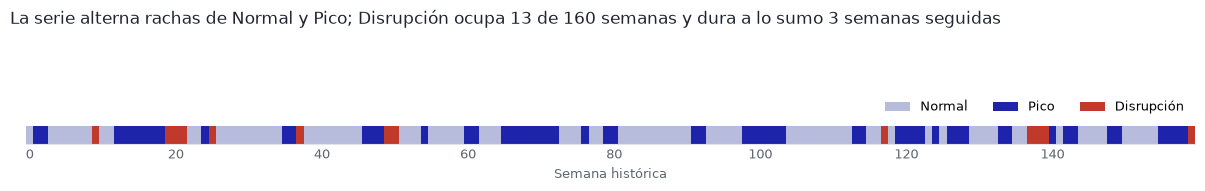

In [2]:
fig, ax = plt.subplots(figsize=(12, 1.9))
codigo = observaciones["state"].map({e: k for k, e in enumerate(ESTADOS)}).to_numpy()
for k, estado in enumerate(ESTADOS):
    semanas_estado = observaciones["period"].to_numpy()[codigo == k]
    ax.bar(semanas_estado, 1, width=1.0, color=COLOR_ESTADO[estado], label=ETIQUETAS[estado], linewidth=0)
ax.set_xlim(-0.5, len(observaciones) - 0.5)
ax.set_yticks([])
ax.set_xlabel("Semana histórica", color=g.MUTED, fontsize=9)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(g.SPINE)
ax.tick_params(length=0, colors=g.MUTED, labelsize=9)
ax.legend(frameon=False, ncol=3, loc="lower right", bbox_to_anchor=(1.0, 1.02), fontsize=9)
es_disrupcion = observaciones["state"].eq("Disrupcion")
racha_disrupcion = int(es_disrupcion.groupby((~es_disrupcion).cumsum()).sum().max())
fig.suptitle(f"La serie alterna rachas de Normal y Pico; Disrupción ocupa {es_disrupcion.sum()} de "
             f"{len(observaciones)} semanas y dura a lo sumo {racha_disrupcion} semanas seguidas",
             fontsize=12, color=g.INK, x=0, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.80))
plt.show()

## Cadena de Markov

Tres estados, en este orden fijo:

* **Normal**: demanda cercana a la habitual, capacidad completa y casi todas las rutas operativas.
* **Pico**: demanda estacional alta y menor capacidad efectiva por saturación.
* **Disrupción**: cortes o fallas que reducen con fuerza la capacidad y la probabilidad de que una ruta opere.

Primero se cuentan las transiciones: $n_{rs}$ es el número de semanas $t$ con estado $r$ seguidas de una semana $t+1$ con estado $s$. Las 160 semanas dan 159 transiciones. Luego cada fila se normaliza por el total de salidas de su estado:

$$\hat P_{rs} = \frac{n_{rs}}{\sum_q n_{rq}}.$$

Si un estado no tuviera ninguna salida observada, su fila no sería estimable: `estimar_matriz` se detiene y no completa con ceros ni inventa una autotransición.

In [3]:
conteos, matriz = mk.estimar_matriz(observaciones)
salidas = conteos.sum(axis=1)
assert conteos.to_numpy().sum() == len(observaciones) - 1
assert list(matriz.index) == list(ESTADOS) and list(matriz.columns) == list(ESTADOS)
assert np.allclose(matriz.sum(axis=1), 1, rtol=0, atol=sim.TOL) and (matriz.to_numpy() >= 0).all()

print(f"Transiciones contadas: {conteos.to_numpy().sum()} (= {len(observaciones)} semanas - 1)")
print("Filas suman 1, probabilidades finitas y no negativas: ok")

nombres = [ETIQUETAS[e] for e in ESTADOS]
tabla_conteos = g.tabla_doble_entrada(
    nombres, nombres, lambda r, s: f"{conteos.iloc[nombres.index(r), nombres.index(s)]}",
    extra_col=("Salidas", lambda r: f"{salidas.iloc[nombres.index(r)]}"),
)
tabla_matriz = g.tabla_doble_entrada(
    nombres, nombres, lambda r, s: f"{matriz.iloc[nombres.index(r), nombres.index(s)]:.4f}",
)
display(HTML(
    "<div style='display:flex; gap:48px; align-items:flex-start'>"
    f"<div><p style='font-weight:600'>Conteos n<sub>rs</sub></p>{tabla_conteos}</div>"
    f"<div><p style='font-weight:600'>Matriz estimada P̂</p>{tabla_matriz}</div></div>"
))

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
matriz_out = matriz.copy()
matriz_out.index.name = "state"
matriz_out.columns.name = None
matriz_out.to_csv(OUTPUTS_DIR / "markov_matrix.csv")

Transiciones contadas: 159 (= 160 semanas - 1)
Filas suman 1, probabilidades finitas y no negativas: ok


**Lectura.** Normal y Pico son persistentes: una semana Normal sigue Normal con probabilidad 0,74 y una de Pico sigue en Pico con 0,64, y por eso la serie forma rachas. Disrupción es más breve: se repite el 42 % de las veces y el 50 % vuelve directamente a Normal. Entrar en Disrupción es poco frecuente (3,4 % desde Normal y 8,6 % desde Pico).

La fila de Disrupción se estima con sólo 12 transiciones, frente a 89 y 58 de las otras dos. Su incertidumbre de estimación es grande: el error estándar binomial de $\hat P_{DD}=0{,}42$ es $\sqrt{0{,}42\cdot 0{,}58/12}\approx 0{,}14$. Esa incertidumbre **no** entra en los intervalos Monte Carlo, que tratan la matriz como fija. La matriz queda congelada aquí, es la que usa toda la campaña y se exporta a `outputs/markov_matrix.csv`.

## Probabilidades a uno y varios pasos

$\hat P_{rs}$ es la probabilidad de pasar de $r$ a $s$ **en una semana**. La probabilidad de pasar de $r$ a $s$ en exactamente $k$ semanas es la entrada $(r,s)$ de la potencia $P^k$ (ecuación de Chapman–Kolmogorov: $P^{k+m}=P^k P^m$).

Si $\pi_t$ es la distribución del estado en la semana $t$, entonces $\pi_{t+1}=\pi_t P$ y

$$\pi_t = \pi_1\, P^{\,t-1}, \qquad \pi_1 = (0,\ 0,\ 1),$$

porque la semana 1 empieza con certeza en Disrupción, el último estado de la serie.

In [4]:
P1, P2, P4 = (mk.potencia(matriz, k) for k in (1, 2, 4))
assert np.allclose(P2, matriz.to_numpy() @ matriz.to_numpy(), rtol=0, atol=sim.TOL)
assert np.allclose(P4, P2.to_numpy() @ P2.to_numpy(), rtol=0, atol=sim.TOL)
for Pk in (P1, P2, P4):
    assert np.allclose(Pk.sum(axis=1), 1, rtol=0, atol=sim.TOL)

tablas = [
    (f"P<sup>{k}</sup> — {k} semana{'s' if k > 1 else ''}", Pk) for k, Pk in ((2, P2), (4, P4))
]
display(HTML(
    "<div style='display:flex; gap:32px; align-items:flex-start; flex-wrap:wrap'>"
    + "".join(
        f"<div><p style='font-weight:600'>{titulo}</p>"
        + g.tabla_doble_entrada(nombres, nombres, lambda r, s, Pk=Pk: f"{Pk.iloc[nombres.index(r), nombres.index(s)]:.4f}")
        + "</div>"
        for titulo, Pk in tablas
    )
    + "</div>"
))

pi1 = mk.distribucion_inicial(ESTADOS, sim.ESTADO_INICIAL)
SEMANAS_CLAVE = [1, 2, 4, 13, 26]
distribuciones = pd.DataFrame(
    {f"semana {t}": mk.distribucion_semana(matriz, pi1, t) for t in SEMANAS_CLAVE}
).T.rename(columns=ETIQUETAS)
assert np.allclose(distribuciones.sum(axis=1), 1, rtol=0, atol=sim.TOL)
print("Distribución del estado en semanas seleccionadas, desde Disrupción:")
distribuciones.round(4)

HaciaDesde,Normal,Pico,Disrupción
Normal,0.6288,0.3128,0.0584
Pico,0.4237,0.4761,0.1002
Disrupción,0.6021,0.2002,0.1976
HaciaDesde,Normal,Pico,Disrupción
Normal,0.5631,0.3573,0.0796
Pico,0.5284,0.3793,0.0923
Disrupción,0.5824,0.3233,0.0943


Distribución del estado en semanas seleccionadas, desde Disrupción:


hacia,Normal,Pico,Disrupción
semana 1,0.0000,0.0000,1.0000
semana 2,0.5000,0.0833,0.4167
semana 4,0.6006,0.2795,0.1199
semana 13,0.5522,0.3624,0.0854
semana 26,0.5522,0.3624,0.0855


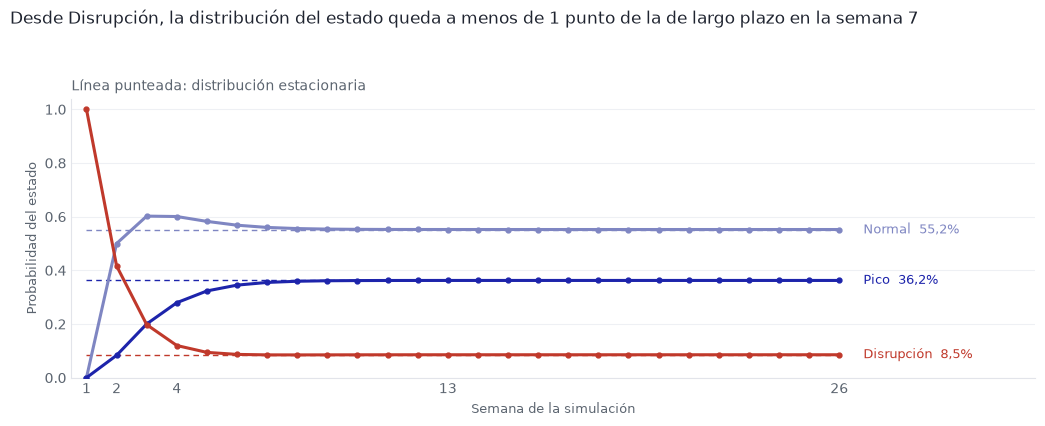

In [5]:
pi_estable = mk.estacionaria(matriz)
semanas_eje = np.arange(1, sim.HORIZONTE + 1)
curvas = pd.DataFrame([mk.distribucion_semana(matriz, pi1, t) for t in semanas_eje], index=semanas_eje)

fig, ax = plt.subplots(figsize=(10.4, 4.3))
for estado in ESTADOS:
    color = COLOR_ESTADO[estado] if estado != "Normal" else "#7F86C2"
    ax.plot(semanas_eje, curvas[estado], color=color, lw=2.2, marker="o", ms=3.5, zorder=3)
    ax.hlines(pi_estable[estado], 1, sim.HORIZONTE, color=color, lw=1, ls=(0, (4, 3)), zorder=2)
    ax.text(sim.HORIZONTE + 0.8, pi_estable[estado], f"{ETIQUETAS[estado]}  {pi_estable[estado]:.1%}".replace(".", ","),
            va="center", fontsize=9.5, color=color)
ax.set_xlim(0.5, sim.HORIZONTE + 6.5)
ax.set_ylim(0, 1.04)
ax.set_xticks([1, 2, 4, 13, 26])
ax.set_xlabel("Semana de la simulación", color=g.MUTED, fontsize=9)
ax.set_ylabel("Probabilidad del estado", color=g.MUTED, fontsize=9)
ax.set_title("Línea punteada: distribución estacionaria", loc="left", fontsize=10, color=g.MUTED)
g.limpiar(ax)
distancia = (curvas - pi_estable).abs().max(axis=1)
semana_cerca = int(distancia[distancia < 0.01].index.min())
fig.suptitle(f"Desde Disrupción, la distribución del estado queda a menos de 1 punto de la de largo plazo en la semana {semana_cerca}",
             fontsize=12.5, color=g.INK, x=0, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

**Lectura.** En la semana 2 la cadena todavía recuerda el arranque: 42 % de seguir en Disrupción y 50 % de haber vuelto a Normal. Normal incluso supera su nivel de largo plazo en las primeras semanas (0,60 en las semanas 3 y 4, frente a 0,55), porque la salida típica de Disrupción es hacia Normal. Pico sube más despacio: desde Disrupción se pasa a Pico con probabilidad 0,08 y casi siempre a través de Normal. En la semana 4 la probabilidad de Disrupción todavía es 12 %, y en las semanas 13 y 26 la distribución difiere de la estacionaria en menos de 0,001.

## Distribución estacionaria

Una distribución $\pi$ es estacionaria si no cambia al avanzar una semana:

$$\pi P = \pi, \qquad \sum_s \pi_s = 1, \qquad \pi_s \ge 0 .$$

Antes de hablar de *la* distribución estacionaria hay que comprobar dos propiedades. Si la cadena es **irreducible** (todo estado alcanza a todo otro), la estacionaria existe y es única. Si además es **aperiódica**, $\pi_t$ converge a $\pi$ desde cualquier estado inicial. Las dos juntas equivalen a que alguna potencia $P^k$ tenga todas sus entradas positivas (cadena *regular*).

El sistema $\pi(P-I)=0$ tiene una ecuación redundante; se resuelve junto con $\sum_s \pi_s = 1$ por mínimos cuadrados y se verifica el residuo.

In [6]:
irreducible = mk.es_irreducible(matriz)
regular = mk.es_regular(matriz)
assert irreducible and regular, "La cadena no cumple las condiciones para una estacionaria única y límite"

residuo = np.abs(pi_estable.to_numpy() @ matriz.to_numpy() - pi_estable.to_numpy()).max()
limite = mk.potencia(matriz, 200)
assert residuo <= sim.TOL and np.allclose(limite.to_numpy(), pi_estable.to_numpy()[None, :], rtol=0, atol=sim.TOL)

print("Irreducible:", irreducible, "   Regular (irreducible y aperiódica):", regular)
print(f"max |πP - π| = {residuo:.2e}    suma = {pi_estable.sum():.10f}")
print("Cada fila de P^200 coincide con π (convergencia desde cualquier estado): ok")

frecuencia_historica = observaciones["state"].value_counts(normalize=True).reindex(ESTADOS)
pd.DataFrame({
    "estacionaria π": pi_estable,
    "frecuencia en la serie histórica": frecuencia_historica,
}).rename(index=ETIQUETAS).round(4)

Irreducible: True    Regular (irreducible y aperiódica): True
max |πP - π| = 5.55e-17    suma = 1.0000000000
Cada fila de P^200 coincide con π (convergencia desde cualquier estado): ok


,estacionaria π,frecuencia en la serie histórica
Normal,0.5522,0.5562
Pico,0.3624,0.3625
Disrupción,0.0855,0.0812


La estacionaria (55,2 % Normal, 36,2 % Pico, 8,5 % Disrupción) es casi igual a la frecuencia de cada estado en la serie (55,6 %, 36,3 %, 8,1 %), como se espera de una matriz estimada con esa misma serie.

### Cuatro distribuciones que no hay que confundir

1. **Distribución inicial** $\pi_1=(0,0,1)$: la semana 1 es Disrupción con certeza. Es una condición del experimento y no se reemplaza por el largo plazo.
2. **Distribución estacionaria** $\pi$: la fracción de tiempo en cada estado en un horizonte muy largo, sin importar dónde empieza la cadena.
3. **Ocupación esperada en 26 semanas**: $\sum_{t=1}^{26}\pi_t$, el número esperado de semanas en cada estado durante el experimento. Como arranca en Disrupción, sobrerrepresenta ese estado frente a $\pi$.
4. **Ocupación observada en la simulación**: el conteo en una muestra finita de trayectorias. Fluctúa alrededor de la ocupación esperada y se compara con ella después de la campaña.

Una **trayectoria** individual es otra cosa: una secuencia concreta de 26 estados. Una trayectoria puede pasar 20 semanas en Pico aunque la probabilidad estacionaria de Pico sea de alrededor del 36,2 %. La persistencia temporal permite rachas largas, y una trayectoria individual no tiene por qué reproducir las proporciones esperadas. Además, la probabilidad de Pico no es la misma en todas las semanas: depende del arranque en Disrupción y converge a la estacionaria.

In [7]:
ocupacion_esperada = mk.ocupacion_esperada(matriz, pi1, sim.HORIZONTE)
assert abs(ocupacion_esperada.sum() - sim.HORIZONTE) <= sim.TOL
tabla_distribuciones = pd.DataFrame({
    "inicial π₁": pi1,
    "estacionaria π": pi_estable,
    "ocupación esperada (fracción de 26 semanas)": ocupacion_esperada / sim.HORIZONTE,
    "ocupación esperada (semanas)": ocupacion_esperada,
}, index=list(ESTADOS)).rename(index=ETIQUETAS)
tabla_distribuciones.round(4)

,inicial π₁,estacionaria π,ocupación esperada (fracción de 26 semanas),ocupación esperada (semanas)
Normal,0.0,0.5522,0.5350,13.9106
Pico,0.0,0.3624,0.3256,8.4666
Disrupción,1.0,0.0855,0.1393,3.6228


### Simular posibles futuros

Una trayectoria tiene 26 semanas y empieza en Disrupción. El estado de la semana fija la media de la demanda, la probabilidad de que una ruta opere y el multiplicador de capacidad. Dado el estado, demandas y disponibilidades se sortean por separado.

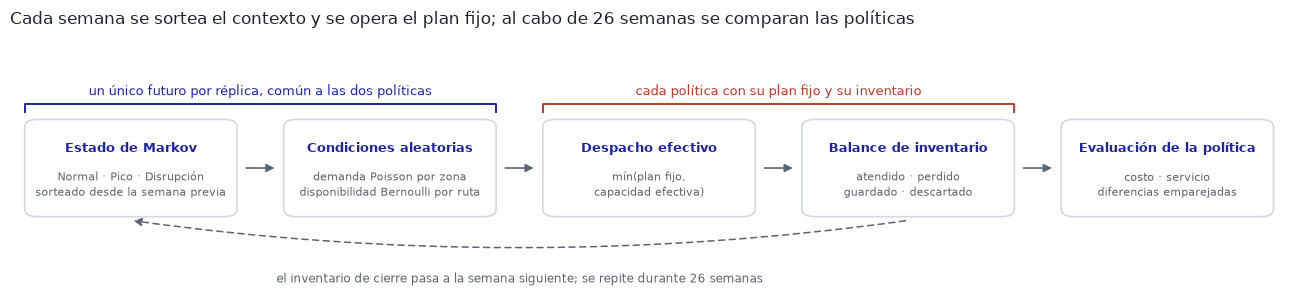

In [8]:
fig, ax = plt.subplots(figsize=(13, 3.0))
g.diagrama_flujo(
    ax,
    [
        ("Estado de Markov", "Normal · Pico · Disrupción\nsorteado desde la semana previa"),
        ("Condiciones aleatorias", "demanda Poisson por zona\ndisponibilidad Bernoulli por ruta"),
        ("Despacho efectivo", "mín(plan fijo,\ncapacidad efectiva)"),
        ("Balance de inventario", "atendido · perdido\nguardado · descartado"),
        ("Evaluación de la política", "costo · servicio\ndiferencias emparejadas"),
    ],
    grupos=[
        (0, 1, "un único futuro por réplica, común a las dos políticas", g.PRIMARY),
        (2, 3, "cada política con su plan fijo y su inventario", g.RED),
    ],
    retorno=(3, 0, f"el inventario de cierre pasa a la semana siguiente; se repite durante {sim.HORIZONTE} semanas"),
)
fig.suptitle("Cada semana se sortea el contexto y se opera el plan fijo; al cabo de 26 semanas se comparan las políticas",
             fontsize=12, color=g.INK, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Parámetros por estado.** El estado de la semana fija tres números: el multiplicador de la demanda media, el multiplicador de la capacidad de cada ruta y la probabilidad de que una ruta opere. Son **supuestos sintéticos** que siguen la descripción cualitativa de cada estado (`data/markov_state_parameters.csv`).

In [9]:
parametros = sim.cargar_parametros(DATA_DIR / "markov_state_parameters.csv")
columnas_parametros = {
    "Multiplicador de demanda": lambda e: f"×{parametros.loc[e, 'demand_multiplier']:.2f}".replace(".", ","),
    "Multiplicador de capacidad": lambda e: f"×{parametros.loc[e, 'capacity_multiplier']:.2f}".replace(".", ","),
    "Disponibilidad de rutas": lambda e: f"{parametros.loc[e, 'route_availability']:.0%}".replace("%", " %"),
}
estado_de = {ETIQUETAS[e]: e for e in ESTADOS}
display(HTML(
    "<p style='font-weight:600'>Parámetros por estado</p>"
    + g.tabla_doble_entrada(list(estado_de), list(columnas_parametros),
                            lambda fila, col: columnas_parametros[col](estado_de[fila]), esquina=g.th("", g.INK))
    + f"<p style='color:{g.MUTED}; font-size:14px'>Demanda media de la zona <i>j</i>: d<sub>j</sub> × multiplicador de demanda. "
    "Capacidad efectiva de la ruta: u<sub>ij</sub> × multiplicador de capacidad si la ruta opera, 0 si no.</p>"
))

def numero(x, columna):
    return (f"{x:.2f}" if columna in ("holding_cost", "waste_cost") else f"{x:g}").replace(".", ",")

columnas_zonas = {
    "Demanda\nnominal\n(u./semana)": "nominal_demand",
    "Penalización\npor faltante\n(pts/u.)": "shortage_penalty",
    "Inventario\ninicial\n(u.)": "initial_inventory",
    "Capacidad de\nalmacenamiento\n(u.)": "storage_capacity",
    "Costo de\nalmacenamiento\n(pts/u./semana)": "holding_cost",
    "Costo de\ndescarte\n(pts/u.)": "waste_cost",
}
(OUTPUTS_DIR / "presentacion").mkdir(parents=True, exist_ok=True)
ruta_zonas = OUTPUTS_DIR / "presentacion" / "parametros_zonas_oscuro.png"
g.tabla_imagen(
    ruta_zonas,
    "Parámetros por zona de la simulación",
    ["Zona"] + list(columnas_zonas),
    [[fila["destination"]] + [numero(fila[c], c) for c in columnas_zonas.values()] for _, fila in destinations.iterrows()],
    nota="Fuente: data/destinations.csv. El almacenamiento se cobra sobre el inventario de cierre de cada semana;\n"
         "el descarte, sobre lo que excede la capacidad de almacenamiento.",
    ancho=11, x_valores=0.25, destacada=None,
)

,Multiplicador de demanda,Multiplicador de capacidad,Disponibilidad de rutas
Normal,"×1,00","×1,00",95 %
Pico,"×1,20","×0,80",90 %
Disrupción,"×1,00","×0,50",50 %


#### 1. Las 26 semanas

La semana 1 es Disrupción, el último estado de la serie. De la semana 2 en adelante, el estado se sortea con la fila correspondiente de la matriz estimada.

In [10]:
rng = np.random.default_rng(sim.SEMILLA_MAESTRA)
trayectoria = pd.DataFrame({
    "semana": np.arange(1, sim.HORIZONTE + 1),
    "estado": sim.trayectoria_estados(rng, matriz),
})
assert len(trayectoria) == sim.HORIZONTE
assert trayectoria["estado"].iloc[0] == "Disrupcion"
rachas = trayectoria.assign(racha=(trayectoria["estado"] != trayectoria["estado"].shift()).cumsum()).groupby("racha").agg(
    desde=("semana", "min"), hasta=("semana", "max"), estado=("estado", "first"))
pd.DataFrame({
    "semanas": [f"{a}" if a == b else f"{a}–{b}" for a, b in zip(rachas["desde"], rachas["hasta"])],
    "estado": rachas["estado"].map(ETIQUETAS),
    "duración": rachas["hasta"] - rachas["desde"] + 1,
}).set_index("semanas")

,estado,duración
semanas,,
1,Disrupción,1
2,Normal,1
3–12,Pico,10
13–17,Normal,5
18–23,Pico,6
24,Disrupción,1
25–26,Normal,2


Ésta es **una** trayectoria ilustrativa, con un generador propio; no forma parte de la campaña. Muestra la persistencia: una vez en Pico, la cadena tiende a quedarse varias semanas. Las distribuciones de la sección anterior describen qué pasa *en promedio* sobre muchas trayectorias como ésta.

#### 2. Demanda

En cada zona, la demanda de la semana es Poisson: $D_{jt} \sim \text{Poisson}(d_j \cdot m^{dem}_{Z_t})$, con $d_j$ la demanda nominal y $m^{dem}$ el `demand_multiplier` del estado. Dado el estado, las cinco zonas se sortean independientes.

#### 3. Disponibilidad

Cada ruta está disponible o no: $A_{ijt} \sim \text{Bernoulli}(\rho_{Z_t})$, con $\rho$ la `route_availability` del estado. Dado el estado, las quince rutas se sortean independientes entre sí, de una semana a otra y de la demanda.

#### 4. Capacidad efectiva

No es otro sorteo: $\tilde u_{ijt} = A_{ijt}\, m^{cap}_{Z_t}\, u_{ij}$. Si la ruta no está disponible, la capacidad es cero; si lo está, la capacidad nominal se multiplica por el `capacity_multiplier` del estado.

#### 5. Un futuro completo

`entorno` arma las 26 semanas de una réplica en este orden: en cada semana $t\ge 2$ sortea el estado desde la fila de $Z_{t-1}$; luego las cinco demandas y después las quince disponibilidades. El futuro **no depende de la política**: se genera una sola vez por réplica y se entrega a las dos.

In [11]:
g.mostrar_fragmento(
    "Fragmento: un futuro por réplica, común a las dos políticas",
    (sim.entorno, "for t in range(horizonte):", "tope = capacidad_efectiva("),
    (sim.campana, "for i, rng in enumerate(generadores):", "fila.update("),
)

**Fragmento: un futuro por réplica, común a las dos políticas**

```python
# src/simulacion.py · entorno()
for t in range(horizonte):
    if t:
        estado = siguiente_estado(rng, matriz, estado)
    fila = parametros.loc[estado]
    pedida = demanda(rng, demanda_nominal, float(fila["demand_multiplier"]))
    abierta = disponibilidad(rng, len(rutas), float(fila["route_availability"]))
    tope = capacidad_efectiva(abierta, capacidad_nominal, float(fila["capacity_multiplier"]))

# src/simulacion.py · campana()
for i, rng in enumerate(generadores):
    futuro = entorno(rng, matriz, rutas, zonas, parametros)
    fila = {"replica": inicio + i, "demanda": float(futuro["demanda"].sum())}
    for politica, flujo in flujos.items():
        metricas = evaluar_plan(flujo, futuro, red)
        metricas.pop("demanda")
        fila.update({f"{clave}_{politica}": valor for clave, valor in metricas.items()})
```

### Operación logística

El plan queda fijo durante las 26 semanas y no se reoptimiza al observar demanda, fallas o estados. Para la política $k$ con flujo planificado $\bar x^k_{ij}$, cada semana:

$$
\begin{aligned}
q^k_{ijt} &= \min\{\bar x^k_{ij},\ \tilde u_{ijt}\}, & R^k_{jt} &= \textstyle\sum_i q^k_{ijt} && \text{despacho real y recepción}\\
B^k_{jt} &= I^k_{j,t-1} + R^k_{jt}, & V^k_{jt} &= \min\{B^k_{jt},\ D_{jt}\} && \text{existencias y demanda atendida}\\
L^k_{jt} &= D_{jt} - V^k_{jt}, & E^k_{jt} &= B^k_{jt} - V^k_{jt} && \text{faltante y sobrante}\\
I^k_{jt} &= \min\{E^k_{jt},\ K_j\}, & W^k_{jt} &= \max\{E^k_{jt} - K_j,\ 0\} && \text{inventario de cierre y descarte}
\end{aligned}
$$

con $I^k_{j0}$ el inventario inicial y $K_j$ la capacidad de almacenamiento. El faltante es demanda **perdida**: no queda como pedido pendiente. El costo de la semana suma transporte sobre lo despachado, penalización por faltante, almacenamiento del inventario de cierre y descarte:

$$C^k = \sum_{t=1}^{26}\Big(\sum_{(i,j)} c_{ij} q^k_{ijt} + \sum_j \big(p_j L^k_{jt} + h_j I^k_{jt} + w_j W^k_{jt}\big)\Big).$$

### Las dos políticas

Las dos políticas salen de la Parte I y no se vuelven a optimizar. La nominal cubre la demanda de una semana típica; el resguardo se calculó con una demanda de diseño 5 % mayor, redondeada hacia arriba.

`cargar_politica` lee cada archivo puente y se detiene si falta, si una ruta está repetida, ausente o sobra, si un flujo no es finito o es negativo, si supera la capacidad nominal de su ruta, si un centro despacha más que su oferta o si `origin`, `destination`, `capacity` o `unit_cost` no coinciden con `routes.csv`. Además se recalcula la huella SHA-256 de cada archivo y se compara con la registrada por la Parte I en `outputs/part1_manifest.json`: si un archivo fue editado a mano, la ejecución se detiene.

In [12]:
ruta_nominal = OUTPUTS_DIR / "part1_solution.csv"
ruta_resguardo = OUTPUTS_DIR / "part1_solution_buffer.csv"
manifiesto_p1 = json.loads((OUTPUTS_DIR / "part1_manifest.json").read_text(encoding="utf-8"))

plan_nominal = cargar_politica(ruta_nominal, routes, origins)
plan_resguardo = cargar_politica(ruta_resguardo, routes, origins)
hashes = {"nominal": sha256(ruta_nominal), "resguardo": sha256(ruta_resguardo)}
for politica, huella in hashes.items():
    registrada = manifiesto_p1["politicas"][politica]["sha256"]
    assert huella == registrada, f"El archivo de la política {politica} no coincide con el exportado por la Parte I"

def costo_del_plan(plan):
    return float((plan["planned_flow"] * plan["unit_cost"]).sum())

for politica, plan in (("nominal", plan_nominal), ("resguardo", plan_resguardo)):
    registrado = manifiesto_p1["politicas"][politica]["costo_transporte"]
    assert abs(costo_del_plan(plan) - registrado) <= sim.TOL

print("Políticas leídas de outputs/: huellas SHA-256 y costos iguales a los registrados por la Parte I; sin reoptimizar")
planes = {"Nominal": ("nominal", plan_nominal), "Resguardo": ("resguardo", plan_resguardo)}
indicadores = {
    "Despacho planificado": lambda clave, plan: f"{plan['planned_flow'].sum():.0f} unidades/semana",
    "Costo determinista del plan": lambda clave, plan: f"{costo_del_plan(plan):.0f} puntos/semana",
    "Faltante frente a su demanda de diseño": lambda clave, plan: f"{manifiesto_p1['politicas'][clave]['faltante']:.0f} unidades",
}
display(HTML(
    "<p style='font-weight:600'>Las dos políticas que se comparan</p>"
    + g.tabla_doble_entrada(list(indicadores), list(planes), lambda fila, col: indicadores[fila](*planes[col]),
                            esquina=g.th("", g.INK))
    + f"<p style='color:{g.MUTED}; font-size:14px'>Resultados de planificación de <b>una semana</b> con datos "
    "deterministas (Parte I). No son los costos de 26 semanas del Monte Carlo que se presentan más adelante.</p>"
))

Políticas leídas de outputs/: huellas SHA-256 y costos iguales a los registrados por la Parte I; sin reoptimizar


,Nominal,Resguardo
Despacho planificado,211 unidades/semana,224 unidades/semana
Costo determinista del plan,818 puntos/semana,892 puntos/semana
Faltante frente a su demanda de diseño,0 unidades,0 unidades


### Control de una semana

Semana fija, no sorteada: la demanda es la nominal, todas las rutas están abiertas y la capacidad efectiva es la nominal. Con el plan nominal leído de la Parte I, todo debe atenderse sin faltante ni descarte, el inventario debe quedar igual al inicial y el transporte debe costar lo mismo que el óptimo de la Parte I. Este límite determinista comprueba el balance antes de usar los multiplicadores de cada estado.

In [13]:
inventario_inicial = destinations.set_index("destination")["initial_inventory"].astype(float)
pedida_nominal = destinations["nominal_demand"].to_numpy()
capacidad_nominal = routes["capacity"].to_numpy()

envio, cuadro, costos, inventario_final = sim.operar_semana(
    plan_nominal, routes, destinations, pedida_nominal, capacidad_nominal, inventario_inicial
)

assert np.allclose(cuadro["faltante"], 0, rtol=0, atol=sim.TOL)
assert np.allclose(cuadro["descarte"], 0, rtol=0, atol=sim.TOL)
assert np.allclose(inventario_final, inventario_inicial, rtol=0, atol=sim.TOL)
assert abs(costos["transporte"] - manifiesto_p1["politicas"]["nominal"]["costo_transporte"]) <= sim.TOL
assert abs(
    costos["almacen"] - float((inventario_inicial * destinations.set_index("destination")["holding_cost"]).sum())
) <= sim.TOL

print(f"Semana determinista con el plan nominal: demanda {cuadro['demanda'].sum():g}, atendida {cuadro['atendido'].sum():g}, "
      f"faltante {cuadro['faltante'].sum():g}, descarte {cuadro['descarte'].sum():g}; inventario final igual al inicial")
print(f"Costo: transporte {costos['transporte']:g} (igual al óptimo de la Parte I) + almacenamiento {costos['almacen']:.2f} "
      f"= {costos['total']:.2f} puntos")

Semana determinista con el plan nominal: demanda 211, atendida 211, faltante 0, descarte 0; inventario final igual al inicial
Costo: transporte 818 (igual al óptimo de la Parte I) + almacenamiento 11.06 = 829.06 puntos


### Dos implementaciones, un mismo resultado

La campaña usa `evaluar_plan` (en `src/simulacion.py`), una versión NumPy más rápida que recorre las mismas ecuaciones sin armar tablas. Para confiar en ella, se evalúa un mismo futuro fijo (el de la réplica 0) con las dos implementaciones y las dos políticas, y se exige que todas las métricas coincidan con tolerancia absoluta $10^{-7}$.

In [14]:
red = sim.red_logistica(routes, destinations)
flujo_nominal = sim.flujo_de(plan_nominal, routes)
flujo_resguardo = sim.flujo_de(plan_resguardo, routes)
futuro_prueba = sim.entorno(sim.crear_generadores(sim.SEMILLA_MAESTRA, 1)[0], matriz, routes, destinations, parametros)
comparaciones = []
for politica, plan, flujo in (("nominal", plan_nominal, flujo_nominal), ("resguardo", plan_resguardo, flujo_resguardo)):
    con_pandas = sim.resumir_operacion(sim.operar(plan, routes, destinations, futuro_prueba))
    con_numpy = sim.evaluar_plan(flujo, futuro_prueba, red)
    for clave in con_pandas:
        comparaciones.append({
            "política": politica, "métrica": clave, "pandas": con_pandas[clave], "numpy": con_numpy[clave],
            "diferencia_absoluta": abs(con_pandas[clave] - con_numpy[clave]),
        })
equivalencia = pd.DataFrame(comparaciones)
assert np.isfinite(equivalencia[["pandas", "numpy"]].to_numpy()).all()
assert equivalencia["diferencia_absoluta"].max() <= sim.TOL
print(f"pandas frente a NumPy: {equivalencia['métrica'].nunique()} métricas × 2 políticas; "
      f"máxima diferencia {equivalencia['diferencia_absoluta'].max():.2e} (tolerancia {sim.TOL:.0e})")

pandas frente a NumPy: 13 métricas × 2 políticas; máxima diferencia 2.27e-13 (tolerancia 1e-07)


### Experimento Monte Carlo

La campaña tiene 1.200 trayectorias de 26 semanas. La semilla maestra es 20260816 y `SeedSequence(20260816).spawn(1200)` da a cada réplica un generador independiente y reproducible: la réplica $r$ usa siempre el mismo generador, se corra en un bloque o en dos.

Cada trayectoria se sortea una sola vez y las dos políticas reciben los mismos estados, demandas, disponibilidades y capacidades efectivas, y arrancan con el mismo inventario inicial. Desde ahí cada política lleva su **propio** inventario, porque despacha cantidades distintas.

**Parámetros por estado.** Los multiplicadores no estaban en el material disponible del caso: son **supuestos sintéticos** (tabla de la sección *Simular posibles futuros*) que siguen la descripción cualitativa de cada estado. Normal queda en el nivel habitual, con capacidad completa y casi todas las rutas abiertas; Pico sube la demanda 20 % y baja la capacidad al 80 %; Disrupción mantiene la demanda y deja la capacidad al 50 % con la mitad de las rutas disponibles. `cargar_parametros` exige los tres estados, sin repetidos ni faltantes, multiplicadores finitos no negativos y disponibilidad en $[0,1]$.

In [15]:
generadores = sim.crear_generadores(sim.SEMILLA_MAESTRA, sim.N_CAMPANA)
flujos = {"nominal": flujo_nominal, "resguardo": flujo_resguardo}

piloto, estados_piloto = sim.campana(
    generadores[:sim.N_PILOTO], matriz, routes, destinations, parametros, flujos, inicio=0
)
print(f"Piloto: {len(piloto)} trayectorias de {sim.HORIZONTE} semanas")

Piloto: 200 trayectorias de 26 semanas


### Piloto de 200

Las primeras 200 trayectorias se usan para comprobar que el modelo no produce valores imposibles, que la semilla repite exactamente una réplica, que toda trayectoria arranca en Disrupción y qué estados aparecen. El piloto **no** se usa para cambiar parámetros, métricas ni la política: si un control falla, la ejecución se detiene; si todos pasan, el protocolo se mantiene sin cambios y la campaña continúa. Las 200 trayectorias siguen formando parte de las 1.200.

In [16]:
sim.chequear(piloto)
assert len(piloto) == sim.N_PILOTO and list(piloto["replica"]) == list(range(sim.N_PILOTO))
assert all(len(e) == sim.HORIZONTE and e[0] == "Disrupcion" for e in estados_piloto)

repetida = sim.entorno(sim.crear_generadores(sim.SEMILLA_MAESTRA, sim.N_CAMPANA)[0], matriz, routes, destinations, parametros)
assert repetida["estado"] == estados_piloto[0]
for politica, flujo in flujos.items():
    assert sim.evaluar_plan(flujo, repetida, red)["costo"] == piloto.loc[0, f"costo_{politica}"]

ocupacion_piloto = sim.ocupacion(estados_piloto)
escala = pd.Series({
    "costo nominal": piloto["costo_nominal"].mean(),
    "costo resguardo": piloto["costo_resguardo"].mean(),
    "servicio nominal": piloto["servicio_nominal"].mean(),
    "servicio resguardo": piloto["servicio_resguardo"].mean(),
})
print("Invariantes, arranque en Disrupción y repetición exacta de la réplica 0: ok")
print("Decisión: el protocolo se mantiene sin cambios y se autoriza el resto de la campaña.")
print("Semanas por estado en el piloto:", ", ".join(f"{ETIQUETAS[e]} {g.miles(n)}" for e, n in ocupacion_piloto.items()))
print(f"Escala del piloto: costo medio {g.miles(escala['costo nominal'])} (nominal) y {g.miles(escala['costo resguardo'])} "
      f"(resguardo); servicio {f'{100 * escala["servicio nominal"]:.2f}'.replace('.', ',')} % y "
      f"{f'{100 * escala["servicio resguardo"]:.2f}'.replace('.', ',')} %")

Invariantes, arranque en Disrupción y repetición exacta de la réplica 0: ok
Decisión: el protocolo se mantiene sin cambios y se autoriza el resto de la campaña.
Semanas por estado en el piloto: Normal 2.813, Pico 1.676, Disrupción 711
Escala del piloto: costo medio 121.180 (nominal) y 101.907 (resguardo); servicio 74,98 % y 80,12 %


### Campaña completa

Las 1.000 réplicas restantes usan los generadores 200 a 1.199, con el mismo protocolo. Se unen al piloto para formar las 1.200.

In [17]:
resto, estados_resto = sim.campana(
    generadores[sim.N_PILOTO:], matriz, routes, destinations, parametros, flujos, inicio=sim.N_PILOTO
)
resultados = pd.concat([piloto, resto], ignore_index=True)
estados_campana = estados_piloto + estados_resto

sim.chequear(resultados)
assert len(resultados) == sim.N_CAMPANA and list(resultados["replica"]) == list(range(sim.N_CAMPANA))
assert len(estados_campana) == sim.N_CAMPANA
print(f"Campaña: {len(resultados)} trayectorias ({sim.N_PILOTO} del piloto + {len(resto)}); invariantes: ok")


Campaña: 1200 trayectorias (200 del piloto + 1000); invariantes: ok


### Ocupación simulada frente a la esperada

La ocupación media de las 1.200 trayectorias debe parecerse a la ocupación esperada que da la cadena, $\sum_{t=1}^{26}\pi_t$. La diferencia es error de muestreo: el intervalo del 95 % de la media simulada debería contener el valor teórico. Es un control de que el simulador recorre la cadena estimada.

In [18]:
semanas_por_trayectoria = pd.DataFrame(
    [pd.Series(e).value_counts().reindex(ESTADOS, fill_value=0) for e in estados_campana]
)
filas = []
for estado in ESTADOS:
    media, error, bajo, alto = sim.intervalo(semanas_por_trayectoria[estado])
    filas.append({
        "estado": ETIQUETAS[estado],
        "esperada (semanas)": ocupacion_esperada[estado],
        "simulada (semanas)": media,
        "IC 95 % inferior": bajo,
        "IC 95 % superior": alto,
        "esperada dentro del IC": bajo <= ocupacion_esperada[estado] <= alto,
        "estacionaria × 26": pi_estable[estado] * sim.HORIZONTE,
    })
assert sim.ocupacion(estados_campana).sum() == sim.N_CAMPANA * sim.HORIZONTE
pd.DataFrame(filas).set_index("estado").round(3)

,esperada (semanas),simulada (semanas),IC 95 % inferior,IC 95 % superior,esperada dentro del IC,estacionaria × 26
estado,,,,,,
Normal,13.911,13.883,13.675,14.092,True,14.356
Pico,8.467,8.515,8.313,8.717,True,9.422
Disrupción,3.623,3.602,3.481,3.723,True,2.222


In [19]:
#| include: false
def tres(x):
    return f"{x:.3f}".replace(".", ",")

(OUTPUTS_DIR / "presentacion").mkdir(parents=True, exist_ok=True)
ruta_ocupacion = OUTPUTS_DIR / "presentacion" / "ocupacion_teorica_simulada_oscuro.png"
g.tabla_imagen(
    ruta_ocupacion,
    "Ocupación en 26 semanas: cadena de Markov frente a simulación",
    ["Estado", "Esperada\n(semanas)", "Simulada\n(semanas)", "IC 95 %\nde la simulada"],
    [[f["estado"], tres(f["esperada (semanas)"]), tres(f["simulada (semanas)"]),
      f"[{tres(f['IC 95 % inferior'])}; {tres(f['IC 95 % superior'])}]"] for f in filas],
    nota="Esperada: suma de las distribuciones πₜ para t = 1, …, 26, con arranque en Disrupción. "
         f"Simulada: media de {f'{len(resultados):,}'.replace(',', '.')} trayectorias.\n"
         + ("El valor esperado cae dentro del intervalo en los tres estados."
            if all(f["esperada dentro del IC"] for f in filas) else "El valor esperado no cae dentro del intervalo en todos los estados."),
    ancho=9.5, x_valores=0.45, destacada=None,
)
ruta_indicadores = OUTPUTS_DIR / "presentacion" / "validacion_simulacion_oscuro.png"
g.indicadores_imagen(
    ruta_indicadores,
    "Resultados de la validación de la simulación",
    [
        ("", f"{len(piloto)}", "réplicas del piloto sin fallas"),
        ("", f"{len(resultados):,}".replace(",", "."), "réplicas en total"),
        ("", g.cientifico(equivalencia["diferencia_absoluta"].max()), "máx. diferencia pandas / NumPy"),
    ],
)

**Lectura.** La ocupación media simulada (13,9 semanas en Normal, 8,5 en Pico y 3,6 en Disrupción) coincide con la esperada y los tres valores teóricos caen dentro de su intervalo: el simulador recorre la cadena estimada. Las trayectorias pasan en promedio 3,6 semanas en Disrupción, 1,4 más que las que indicaría la estacionaria ($0{,}085 \times 26 \approx 2{,}2$): en un horizonte de 26 semanas, el arranque en Disrupción pesa y no debe reemplazarse por el largo plazo.

### Comparación de políticas

Para cada réplica $r$ y cada métrica se calcula la diferencia emparejada $\Delta_r = \text{métrica}^{\text{resguardo}}_r - \text{métrica}^{\text{nominal}}_r$. Una diferencia de costo negativa favorece al resguardo; una de servicio positiva también. Se informa la media $\bar\Delta$, el error estándar $s_\Delta/\sqrt{n}$ calculado **sobre las diferencias** y el intervalo $\bar\Delta \pm t_{0{,}975;\,n-1}\, s_\Delta/\sqrt n$ con $n=1.200$.

Las métricas por trayectoria son:

- **Costo total**: suma de las 26 semanas, en puntos logísticos.
- **Nivel de servicio**: $\sum_{t,j} V_{jt} / \sum_{t,j} D_{jt}$, ponderado por demanda; no es el promedio de los servicios semanales.
- **Unidades faltantes**: demanda perdida en las 26 semanas.
- **Probabilidad de algún faltante**: indicador 0/1 de que hubo al menos una semana con faltante; su media es una proporción.
- **Fracción de semanas con faltante**.
- **Inventario medio**: inventario de cierre sumado entre zonas y promediado en las 26 semanas.
- **Descarte**: unidades descartadas en la trayectoria.

In [20]:
comparacion = sim.comparacion_emparejada(resultados)
resultados.to_csv(OUTPUTS_DIR / "montecarlo_summary.csv", index=False)
comparacion.to_csv(OUTPUTS_DIR / "paired_comparison.csv", index=False)
comparacion.set_index("metrica").round(4)

,nominal,resguardo,diferencia,error_estandar,ic_inferior,ic_superior
metrica,,,,,,
Costo total,122539.8271,103122.9675,-19416.8596,62.2855,-19539.0602,-19294.6590
Nivel de servicio,0.7464,0.7980,0.0516,0.0001,0.0514,0.0519
Unidades faltantes,1488.4262,1186.1120,-302.3142,0.8943,-304.0687,-300.5596
Probabilidad de algún faltante,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
Fracción de semanas con faltante,0.9437,0.8374,-0.1062,0.0024,-0.1108,-0.1016
Inventario medio,13.7141,28.5975,14.8834,0.2788,14.3365,15.4304
Descarte,0.0267,1.4504,1.4238,0.1576,1.1145,1.7330


### Resumen de resultados

Las cuatro métricas principales, como media de las 1.200 trayectorias. La diferencia es resguardo − nominal y se calcula con los valores sin redondear.

In [21]:
por_metrica = comparacion.set_index("metrica")
def signo(texto):
    return texto.replace("-", "−") if texto.startswith("-") else "+" + texto

resumen_metricas = {
    "Costo medio en 26 semanas (puntos)": (
        "Costo total", lambda v: g.miles(v), lambda d: signo(g.miles(d))),
    "Nivel de servicio": (
        "Nivel de servicio", lambda v: f"{100 * v:.2f} %".replace(".", ","),
        lambda d: signo(f"{100 * d:.2f}".replace(".", ",")) + " p. p."),
    "Unidades faltantes por trayectoria": (
        "Unidades faltantes", lambda v: g.miles(v), lambda d: signo(g.miles(d))),
    "Semanas con faltante": (
        "Fracción de semanas con faltante", lambda v: f"{100 * v:.2f} %".replace(".", ","),
        lambda d: signo(f"{100 * d:.2f}".replace(".", ",")) + " p. p."),
}
def celda_resumen(nombre, columna):
    metrica, valor, diferencia = resumen_metricas[nombre]
    if columna == "Diferencia":
        return f"<b>{diferencia(por_metrica.loc[metrica, 'diferencia'])}</b>"
    return valor(por_metrica.loc[metrica, columna.lower()])

def ic(metrica, escala=1.0, decimales=0, unidad=""):
    bajo, alto = (escala * por_metrica.loc[metrica, c] for c in ("ic_inferior", "ic_superior"))
    formato = lambda v: signo(g.miles(v, decimales)) + unidad
    return f"[{formato(bajo)}; {formato(alto)}]"

display(HTML(
    "<p style='font-weight:600'>Nominal frente a resguardo: 1.200 trayectorias de 26 semanas</p>"
    + g.tabla_doble_entrada(list(resumen_metricas), ["Nominal", "Resguardo", "Diferencia"], celda_resumen,
                            esquina=g.th("", g.INK))
    + f"<p style='color:{g.MUTED}; font-size:14px'>Intervalos del 95 % de la diferencia emparejada: "
    f"costo {ic('Costo total')} puntos; servicio {ic('Nivel de servicio', 100, 2, ' p. p.')}; "
    f"faltante {ic('Unidades faltantes')} unidades; semanas con faltante "
    f"{ic('Fracción de semanas con faltante', 100, 2, ' p. p.')}.</p>"
))

,Nominal,Resguardo,Diferencia
Costo medio en 26 semanas (puntos),122.540,103.123,−19.417
Nivel de servicio,"74,64 %","79,80 %","+5,16 p. p."
Unidades faltantes por trayectoria,1.488,1.186,−302
Semanas con faltante,"94,37 %","83,74 %","−10,62 p. p."


In [22]:
#| include: false
(OUTPUTS_DIR / "presentacion").mkdir(parents=True, exist_ok=True)

centros, zonas = list(origins["origin"]), list(destinations["destination"])
distribucion = plan_resguardo.pivot(index="origin", columns="destination", values="planned_flow").reindex(
    index=centros, columns=zonas, fill_value=0.0)
assert abs(distribucion.to_numpy().sum() - plan_resguardo["planned_flow"].sum()) <= sim.TOL
ruta_distribucion = OUTPUTS_DIR / "presentacion" / "distribucion_resguardo_claro.png"
g.tabla_imagen(
    ruta_distribucion,
    "Distribución semanal recomendada (plan de resguardo)",
    ["Centro / Zona"] + zonas + ["Total"],
    [[centro] + [g.etiqueta(distribucion.loc[centro, z]) for z in zonas] + [g.etiqueta(distribucion.loc[centro].sum())]
     for centro in centros]
    + [["Total"] + [g.etiqueta(distribucion[z].sum()) for z in zonas] + [g.etiqueta(distribucion.to_numpy().sum())]],
    nota="Despacho semanal planificado, en unidades logísticas equivalentes. Son flujos fijos: el despacho real "
         "queda limitado\npor la capacidad de cada ruta en la semana.",
    tema="claro", ancho=9.0, x_valores=0.3, destacada=None, total=True,
)

costo_plan = {clave: costo_del_plan(plan) for clave, plan in (("nominal", plan_nominal), ("resguardo", plan_resguardo))}
costo = por_metrica.loc["Costo total"]
servicio = por_metrica.loc["Nivel de servicio"]
faltante = por_metrica.loc["Unidades faltantes"]
porcentaje = lambda v: f"{100 * v:.2f} %".replace(".", ",")
ruta_evidencia = OUTPUTS_DIR / "presentacion" / "evidencia_decision_claro.png"
g.indicadores_imagen(
    ruta_evidencia,
    "Evidencia que respalda la recomendación",
    [
        ("Costo determinista de planificación", f"{g.miles(costo_plan['nominal'])} → {g.miles(costo_plan['resguardo'])}",
         f"{signo(g.miles(costo_plan['resguardo'] - costo_plan['nominal']))} puntos por semana de transporte planificado"),
        ("Costo total simulado", signo(f"{100 * costo['diferencia'] / costo['nominal']:.1f}".replace(".", ",")) + " %",
         f"{g.miles(-costo['diferencia'])} puntos menos por trayectoria de 26 semanas"),
        ("Nivel de servicio", signo(f"{100 * servicio['diferencia']:.2f}".replace(".", ",")) + " p. p.",
         f"{porcentaje(servicio['nominal'])} → {porcentaje(servicio['resguardo'])}"),
        ("Demanda no atendida", signo(g.miles(faltante["diferencia"])), "unidades promedio por trayectoria"),
    ],
    tema="claro", ancho=9.0, columnas=2,
    nota=f"Resultados de {g.miles(len(resultados))} réplicas Monte Carlo emparejadas de {sim.HORIZONTE} semanas. "
         f"IC 95 % de la diferencia de costo\n(resguardo − nominal): {ic('Costo total')} puntos.",
)

In [23]:
def error_independiente(clave):
    a, b = resultados[f"{clave}_nominal"], resultados[f"{clave}_resguardo"]
    return float(np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b)))

eficiencia = pd.DataFrame([
    {
        "métrica": nombre,
        "correlación entre políticas": resultados[f"{clave}_nominal"].corr(resultados[f"{clave}_resguardo"]),
        "error estándar emparejado": comparacion.set_index("metrica").loc[nombre, "error_estandar"],
        "error estándar si fueran muestras independientes": error_independiente(clave),
    }
    for clave, nombre in [("costo", "Costo total"), ("servicio", "Nivel de servicio"), ("faltante", "Unidades faltantes")]
]).set_index("métrica")
eficiencia["reducción del error"] = eficiencia["error estándar si fueran muestras independientes"] / eficiencia["error estándar emparejado"]
eficiencia.round(4)

,correlación entre políticas,error estándar emparejado,error estándar si fueran muestras independientes,reducción del error
métrica,,,,
Costo total,0.9969,62.2855,1060.2899,17.0231
Nivel de servicio,0.9973,0.0001,0.0025,19.0290
Unidades faltantes,0.9970,0.8943,15.5836,17.4258


**Por qué emparejar.** En cada réplica las dos políticas enfrentan el mismo futuro, así que sus resultados están casi perfectamente correlacionados (0,997): una trayectoria con muchas semanas de Pico o Disrupción es cara para ambas. Al restar dentro de cada réplica, esa variación común se cancela y queda el efecto de la política. El error estándar de la diferencia de costo es 62 puntos; con futuros independientes para cada política sería de unos 1.060 puntos, unas 17 veces mayor, y harían falta del orden de 290 veces más réplicas para la misma precisión. La comparación principal usa sólo el intervalo emparejado; esta tabla cuantifica la ganancia de los números aleatorios comunes.

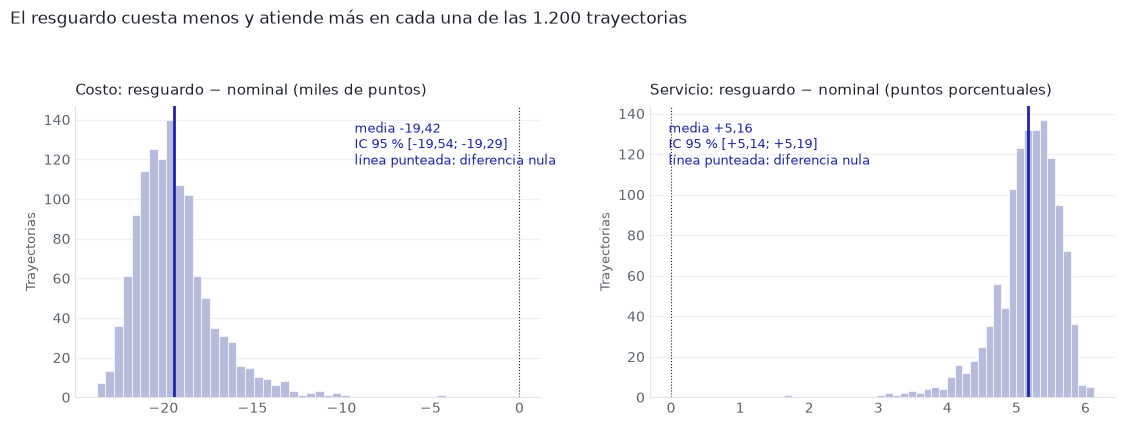

Trayectorias con menor costo en resguardo: 1200 de 1200
Trayectorias con mayor servicio en resguardo: 1200 de 1200


In [24]:
diferencia_costo = resultados["costo_resguardo"] - resultados["costo_nominal"]
diferencia_servicio = resultados["servicio_resguardo"] - resultados["servicio_nominal"]
fila_costo = comparacion.set_index("metrica").loc["Costo total"]
fila_servicio = comparacion.set_index("metrica").loc["Nivel de servicio"]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3))
for ax, datos, fila, escala_txt, titulo in (
    (axes[0], diferencia_costo / 1000, fila_costo, 1000, "Costo: resguardo − nominal (miles de puntos)"),
    (axes[1], diferencia_servicio * 100, fila_servicio, 0.01, "Servicio: resguardo − nominal (puntos porcentuales)"),
):
    ax.hist(datos, bins=40, color=g.NOMINAL, edgecolor="white", linewidth=0.5, zorder=2)
    media = fila["diferencia"] / escala_txt
    ax.axvline(media, color=g.PRIMARY, lw=2, zorder=3)
    ax.axvline(0, color=g.INK, lw=0.8, ls=":", zorder=3)
    ax.set_title(titulo, loc="left", fontsize=10.5, color=g.INK, pad=8)
    ax.set_ylabel("Trayectorias", color=g.MUTED, fontsize=9)
    ax.text(0.60 if ax is axes[0] else 0.04, 0.95,
            f"media {media:+.2f}".replace(".", ",")
            + f"\nIC 95 % [{fila['ic_inferior'] / escala_txt:+.2f}; {fila['ic_superior'] / escala_txt:+.2f}]".replace(".", ",")
            + "\nlínea punteada: diferencia nula",
            transform=ax.transAxes, va="top", ha="left", fontsize=9, color=g.PRIMARY)
    g.limpiar(ax)
gana = (diferencia_costo < 0).mean()
mejor = (diferencia_servicio > 0).mean()
if gana == 1 and mejor == 1:
    titulo_dif = f"El resguardo cuesta menos y atiende más en cada una de las {len(resultados):,} trayectorias".replace(",", ".")
else:
    titulo_dif = f"El resguardo cuesta menos en {gana:.0%} de las trayectorias y atiende más en {mejor:.0%}".replace(".", ",")
fig.suptitle(titulo_dif,
             fontsize=12.5, color=g.INK, x=0, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()
print(f"Trayectorias con menor costo en resguardo: {(diferencia_costo < 0).sum()} de {len(resultados)}")
print(f"Trayectorias con mayor servicio en resguardo: {(diferencia_servicio > 0).sum()} de {len(resultados)}")

,Nominal,Resguardo
Transporte,16961.6,18749.2
Penalización por faltante,105452.7,84109.6
Almacenamiento,125.5,263.1
Descarte,0.0,1.0


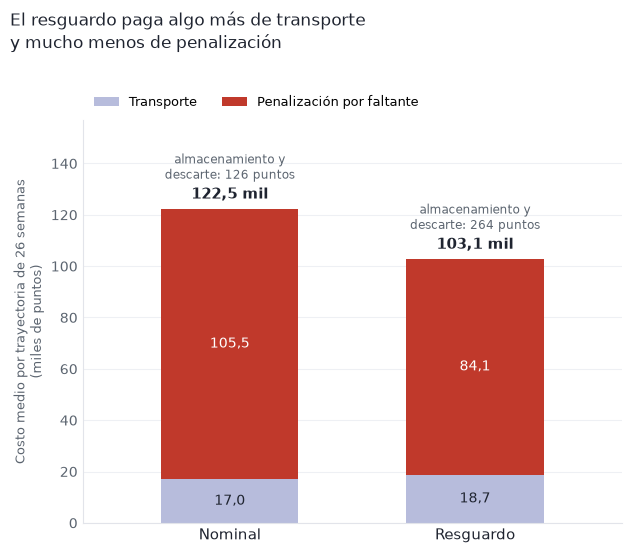

In [25]:
componentes = [("transporte", "Transporte"), ("faltante", "Penalización por faltante"),
               ("almacen", "Almacenamiento"), ("descarte", "Descarte")]
medias = pd.DataFrame({
    politica: [resultados[f"costo_{c}_{politica}"].mean() for c, _ in componentes] for politica in sim.POLITICAS
}, index=[n for _, n in componentes])
display(medias.round(1).rename(columns={"nominal": "Nominal", "resguardo": "Resguardo"}))

fig, ax = plt.subplots(figsize=(6.4, 5.6))
visibles = medias.iloc[:2]
otros = medias.iloc[2:].sum()
colores = [g.NOMINAL, g.ALERT]
for x_, politica in enumerate(["nominal", "resguardo"]):
    base = 0.0
    for (componente, valor), color in zip(visibles[politica].items(), colores):
        ax.bar(x_, valor / 1000, bottom=base, color=color, width=0.56, zorder=2,
               label=componente if x_ == 0 else None)
        ax.text(x_, base + valor / 2000, f"{valor / 1000:.1f}".replace(".", ","), ha="center", va="center",
                fontsize=10, color="white" if color != g.NOMINAL else g.INK)
        base += valor / 1000
    total = medias[politica].sum() / 1000
    ax.text(x_, base + 2.5, f"{total:.1f} mil".replace(".", ","), ha="center", va="bottom",
            fontsize=11, color=g.INK, fontweight="bold")
    ax.text(x_, base + 10, f"almacenamiento y\ndescarte: {otros[politica]:.0f} puntos", ha="center", va="bottom",
            fontsize=8.5, color=g.MUTED, linespacing=1.3)
ax.set_xticks([0, 1], ["Nominal", "Resguardo"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(0, medias.sum().max() / 1000 * 1.28)
ax.set_ylabel("Costo medio por trayectoria de 26 semanas\n(miles de puntos)", color=g.MUTED, fontsize=9)
g.limpiar(ax)
ax.tick_params(axis="x", colors=g.INK, labelsize=11)
ax.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
fig.suptitle("El resguardo paga algo más de transporte\ny mucho menos de penalización",
             fontsize=12.5, color=g.INK, x=0.02, ha="left", linespacing=1.3)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

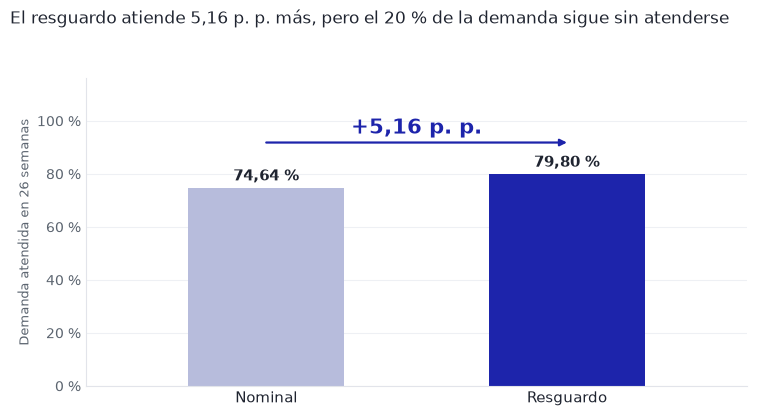

IC 95 % de la diferencia de servicio: [+5,14 p. p.; +5,19 p. p.]


In [26]:
servicio_medio = por_metrica.loc["Nivel de servicio", ["nominal", "resguardo"]].astype(float)
delta_servicio = float(por_metrica.loc["Nivel de servicio", "diferencia"])
fig, ax = plt.subplots(figsize=(7.6, 4.2))
pos = np.array([0, 1])
ax.bar(pos, 100 * servicio_medio.to_numpy(), width=0.52, color=[g.NOMINAL, g.PRIMARY], zorder=2)
for x_, v in zip(pos, servicio_medio):
    ax.text(x_, 100 * v + 1.5, f"{100 * v:.2f} %".replace(".", ","), ha="center", va="bottom",
            fontsize=11, color=g.INK, fontweight="bold")
tope = 100 * servicio_medio.max() + 13
ax.annotate("", xy=(1, tope - 1), xytext=(0, tope - 1),
            arrowprops=dict(arrowstyle="-|>", color=g.PRIMARY, lw=1.6, shrinkA=0, shrinkB=0))
ax.text(0.5, tope + 0.5, f"{100 * delta_servicio:+.2f}".replace(".", ",") + " p. p.", ha="center", va="bottom",
        fontsize=15, color=g.PRIMARY, fontweight="bold")
ax.set_xticks(pos, ["Nominal", "Resguardo"])
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(0, 116)
ax.set_yticks(range(0, 101, 20), [f"{v} %" for v in range(0, 101, 20)])
ax.set_ylabel("Demanda atendida en 26 semanas", color=g.MUTED, fontsize=9)
g.limpiar(ax)
ax.tick_params(axis="x", colors=g.INK, labelsize=11)
sin_atender = 1 - servicio_medio["resguardo"]
fig.suptitle(f"El resguardo atiende {100 * delta_servicio:.2f}".replace(".", ",")
             + f" p. p. más, pero el {100 * sin_atender:.0f} % de la demanda sigue sin atenderse",
             fontsize=12, color=g.INK, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()
print(f"IC 95 % de la diferencia de servicio: {ic('Nivel de servicio', 100, 2, ' p. p.')}")

In [27]:
sin_faltante = {p: int((resultados[f"probabilidad_faltante_{p}"] == 0).sum()) for p in sim.POLITICAS}
n = len(resultados)
cota = {p: float(beta.ppf(0.95, k + 1, n - k)) if k < n else 1.0 for p, k in sin_faltante.items()}
pd.DataFrame({
    "trayectorias sin ningún faltante": sin_faltante,
    "proporción observada": {p: k / n for p, k in sin_faltante.items()},
    "cota superior 95 % (Clopper–Pearson, unilateral)": cota,
}).rename(index={"nominal": "Nominal", "resguardo": "Resguardo"}).round(5)

,trayectorias sin ningún faltante,proporción observada,"cota superior 95 % (Clopper–Pearson, unilateral)"
Nominal,0,0.0,0.00249
Resguardo,0,0.0,0.00249


### Cómo leer estos resultados

**Intervalos emparejados.** El resguardo reduce el costo total medio en 19.417 puntos por trayectoria de 26 semanas, con IC 95 % $[-19.539;\ -19.295]$, y mejora el nivel de servicio en 5,16 puntos porcentuales, con IC $[5{,}14;\ 5{,}19]$. Si la campaña se repitiera con otras semillas, el 95 % de los intervalos construidos así contendría la diferencia media verdadera **del modelo simulado**. Ningún intervalo de costo o servicio toca el cero, y el resguardo es más barato y atiende más en cada una de las 1.200 trayectorias.

**Significancia no es importancia.** Con 1.200 réplicas emparejadas el error estándar es tan chico que casi cualquier diferencia resulta estadísticamente significativa. Para decidir importa la magnitud: aquí la ventaja es grande (16 % del costo nominal y 5 puntos de servicio), pero ese tamaño depende de los supuestos.

**Una media menor no basta.** El 86 % del costo simulado de la política nominal es penalización por faltante, un costo social asignado y no un gasto contable. En lo que sí se gasta, el resguardo es más caro: unos 1.790 puntos más de transporte por trayectoria (+11 %), el doble de inventario medio y algo de descarte. Si la penalización estuviera sobrevaluada, la ventaja se achicaría; la sección de sensibilidad lo cuantifica. Tampoco basta para declarar aceptable una política: hace falta compararla con un objetivo de servicio.

**Probabilidad de algún faltante igual a 1.** En las 1.200 trayectorias de ambas políticas hubo al menos una semana con faltante. Por eso la diferencia y su error estándar son exactamente cero y el intervalo t es degenerado: no informa nada. Es esperable, porque la semana 1 empieza en Disrupción, con la capacidad al 50 % y la mitad de las rutas caídas, y ninguno de los dos planes deja margen para absorberlo; además, en Pico la demanda media (253 unidades por semana) supera lo que repone cada plan (211 o 224) y aun la oferta total de los centros (230), así que una racha de Pico termina por agotar el inventario acumulado. Que no se haya observado ninguna trayectoria sin faltante no prueba que la probabilidad sea exactamente 100 %: con 0 casos en 1.200, la cota superior unilateral del 95 % (Clopper–Pearson) para la probabilidad de una trayectoria sin faltante es 0,25 %. La lectura correcta es "es casi seguro que habrá alguna semana con faltante", no "es imposible evitarlo".

**Qué no miden estos intervalos.** Capturan el error de simulación **condicional** a la matriz estimada, a los multiplicadores por estado, a las penalizaciones y a la oferta reconstruida. No capturan si los multiplicadores supuestos y la oferta reconstruida representan la realidad, ni la incertidumbre de haber estimado la matriz con 159 transiciones (sólo 12 desde Disrupción). Un intervalo angosto dice que la simulación está bien resuelta, no que la conclusión valga fuera del modelo.

### Análisis de sensibilidad (opcional, separado del experimento de referencia)

**Qué se calcula.** Los parámetros por estado y las penalizaciones son supuestos. Para ver si el **orden** entre las dos políticas depende de ellos, se repite la campaña de 1.200 trayectorias cambiando un supuesto por vez. Las dos políticas siguen fijas: no se reoptimizan con los parámetros nuevos.

**Qué se empareja y qué no.** Cada variante usa la misma semilla maestra y el mismo protocolo, y **dentro de cada variante** nominal y resguardo enfrentan exactamente el mismo futuro: la diferencia y su intervalo son emparejados, como en la referencia. **Entre variantes** no se garantiza el mismo futuro. Cambiar las penalizaciones no altera ningún sorteo, así que esas variantes reproducen los futuros de la referencia. Cambiar la disponibilidad conserva estados y demandas pero cambia qué rutas operan. Cambiar la demanda de Pico cambia cuántos números consume el sorteo Poisson y desincroniza los estados siguientes. Por eso las diferencias **entre** variantes no son comparaciones emparejadas y se leen sólo como cambios de magnitud.

Esta sección **no** modifica la matriz, los parámetros, las políticas ni los resultados de referencia, que son los que se exportan; sus tablas no se guardan en `outputs/`, salvo una copia de la tabla resumen en tema oscuro para la presentación (`outputs/presentacion/`).

In [28]:
def variante_parametros(cambios):
    tabla = parametros.copy()
    for (estado, columna), valor in cambios.items():
        tabla.loc[estado, columna] = valor
    tabla["route_availability"] = tabla["route_availability"].clip(0, 1)
    return tabla

disponibilidad_base = parametros["route_availability"]
variantes = {
    "Referencia": (parametros, destinations),
    "Disponibilidad −0,05 en cada estado": (variante_parametros({(e, "route_availability"): disponibilidad_base[e] - 0.05 for e in ESTADOS}), destinations),
    "Disponibilidad +0,05 en cada estado": (variante_parametros({(e, "route_availability"): disponibilidad_base[e] + 0.05 for e in ESTADOS}), destinations),
    "Multiplicador de demanda en Pico 1,10 (ref. 1,20)": (variante_parametros({("Pico", "demand_multiplier"): 1.10}), destinations),
    "Multiplicador de demanda en Pico 1,30 (ref. 1,20)": (variante_parametros({("Pico", "demand_multiplier"): 1.30}), destinations),
    "Penalizaciones ×0,5": (parametros, destinations.assign(shortage_penalty=destinations["shortage_penalty"] * 0.5)),
    "Penalizaciones ×1,5": (parametros, destinations.assign(shortage_penalty=destinations["shortage_penalty"] * 1.5)),
}
filas = []
for nombre, (param_v, zonas_v) in variantes.items():
    tabla_v, _ = sim.campana(sim.crear_generadores(sim.SEMILLA_MAESTRA, sim.N_CAMPANA), matriz, routes, zonas_v, param_v, flujos)
    sim.chequear(tabla_v)
    comp = sim.comparacion_emparejada(tabla_v).set_index("metrica")
    costo, servicio = comp.loc["Costo total"], comp.loc["Nivel de servicio"]
    filas.append({
        "variante": nombre,
        "costo nominal": costo["nominal"], "costo resguardo": costo["resguardo"],
        "Δ costo": costo["diferencia"], "IC 95 % inf": costo["ic_inferior"], "IC 95 % sup": costo["ic_superior"],
        "resguardo más barato": costo["ic_superior"] < 0,
        "servicio nominal (%)": 100 * servicio["nominal"], "servicio resguardo (%)": 100 * servicio["resguardo"],
        "Δ servicio (p. p.)": 100 * servicio["diferencia"],
        "IC 95 % inf (p. p.)": 100 * servicio["ic_inferior"], "IC 95 % sup (p. p.)": 100 * servicio["ic_superior"],
        "resguardo atiende más": servicio["ic_inferior"] > 0,
    })
sensibilidad = pd.DataFrame(filas).set_index("variante")
assert np.isclose(sensibilidad.loc["Referencia", "Δ costo"], comparacion.set_index("metrica").loc["Costo total", "diferencia"], rtol=0, atol=1e-6)

# Con planes y futuros fijos, Δ(f) = a + b·f: a = diferencia de transporte, almacenamiento y descarte,
# b = diferencia de penalización (resguardo − nominal). Se anula en f* = −a / b.
b = (resultados["costo_faltante_resguardo"] - resultados["costo_faltante_nominal"]).mean()
a = comparacion.set_index("metrica").loc["Costo total", "diferencia"] - b
assert b < 0 < a, "Se esperaba un resguardo con menos penalización y más costo operativo"
for factor, nombre in ((0.5, "Penalizaciones ×0,5"), (1.5, "Penalizaciones ×1,5")):
    assert np.isclose(a + b * factor, sensibilidad.loc[nombre, "Δ costo"], rtol=0, atol=1e-6)
factor_equilibrio = -a / b
print(f"Δ costo(f) = {a:.1f} {b:+.1f}·f   →   se anula con un factor de penalización f* ≈ {factor_equilibrio:.3f}".replace(".", ","))

columnas_costo = ["costo nominal", "costo resguardo", "Δ costo", "IC 95 % inf", "IC 95 % sup", "resguardo más barato"]
columnas_servicio = ["servicio nominal (%)", "servicio resguardo (%)", "Δ servicio (p. p.)",
                     "IC 95 % inf (p. p.)", "IC 95 % sup (p. p.)", "resguardo atiende más"]
display(HTML("<p style='font-weight:600'>Nivel de servicio</p>"))
display(sensibilidad[columnas_servicio].round(2))

Δ costo(f) = 1926,3 -21343,2·f   →   se anula con un factor de penalización f* ≈ 0,090


,servicio nominal (%),servicio resguardo (%),Δ servicio (p. p.),IC 95 % inf (p. p.),IC 95 % sup (p. p.),resguardo atiende más
variante,,,,,,
Referencia,74.64,79.80,5.16,5.14,5.19,True
"Disponibilidad −0,05 en cada estado",70.54,75.50,4.96,4.94,4.98,True
"Disponibilidad +0,05 en cada estado",78.75,84.04,5.29,5.25,5.33,True
"Multiplicador de demanda en Pico 1,10 (ref. 1,20)",77.00,82.27,5.27,5.24,5.30,True
"Multiplicador de demanda en Pico 1,30 (ref. 1,20)",72.48,77.53,5.05,5.03,5.07,True
"Penalizaciones ×0,5",74.64,79.80,5.16,5.14,5.19,True
"Penalizaciones ×1,5",74.64,79.80,5.16,5.14,5.19,True


In [29]:
nombres_cortos = {
    "Referencia": "Referencia",
    "Disponibilidad −0,05 en cada estado": "Disponibilidad de rutas −5 p. p.",
    "Disponibilidad +0,05 en cada estado": "Disponibilidad de rutas +5 p. p.",
    "Multiplicador de demanda en Pico 1,10 (ref. 1,20)": "Multiplicador de demanda en Pico 1,10",
    "Multiplicador de demanda en Pico 1,30 (ref. 1,20)": "Multiplicador de demanda en Pico 1,30",
    "Penalizaciones ×0,5": "Penalizaciones por faltante ×0,5",
    "Penalizaciones ×1,5": "Penalizaciones por faltante ×1,5",
}
assert set(nombres_cortos) == set(sensibilidad.index)
variante_de = {corto: largo for largo, corto in nombres_cortos.items()}
columnas_resumen = {
    "Ventaja de costo del resguardo (puntos)": lambda v: f"<b>{g.miles(-sensibilidad.loc[v, 'Δ costo'])}</b>",
    "IC 95 %": lambda v: f"[{g.miles(-sensibilidad.loc[v, 'IC 95 % sup'])}; {g.miles(-sensibilidad.loc[v, 'IC 95 % inf'])}]",
}
display(HTML(
    "<p style='font-weight:600'>Resumen del análisis de sensibilidad</p>"
    + g.tabla_doble_entrada(list(variante_de), list(columnas_resumen),
                            lambda fila, col: columnas_resumen[col](variante_de[fila]), esquina=g.th("", g.INK))
    + f"<p style='color:{g.MUTED}; font-size:14px'>Ventaja = costo nominal − costo resguardo, media de 1.200 "
    "trayectorias de 26 semanas; un valor positivo favorece al resguardo. Planes fijos de la Parte I en todas las variantes.</p>"
))

(OUTPUTS_DIR / "presentacion").mkdir(parents=True, exist_ok=True)
ruta_oscura = OUTPUTS_DIR / "presentacion" / "sensibilidad_oscuro.png"
g.tabla_imagen(
    ruta_oscura,
    "Análisis de sensibilidad",
    ["Variante", "Ventaja de costo del resguardo (puntos)", "IC 95 %"],
    [[corto] + [columnas_resumen[c](largo).replace("<b>", "").replace("</b>", "") for c in columnas_resumen]
     for corto, largo in variante_de.items()],
    nota="Ventaja = costo nominal − costo resguardo, media de 1.200 trayectorias de 26 semanas. Planes fijos de la Parte I.",
)

,Ventaja de costo del resguardo (puntos),IC 95 %
Referencia,19.417,[19.295; 19.539]
Disponibilidad de rutas −5 p. p.,18.697,[18.599; 18.794]
Disponibilidad de rutas +5 p. p.,19.779,[19.604; 19.953]
"Multiplicador de demanda en Pico 1,10",19.149,[19.021; 19.277]
"Multiplicador de demanda en Pico 1,30",19.581,[19.464; 19.698]
"Penalizaciones por faltante ×0,5",8.745,[8.684; 8.806]
"Penalizaciones por faltante ×1,5",30.088,[29.905; 30.272]


**Lectura.** En las seis variantes el resguardo sigue siendo más barato y con mejor servicio, y en cada una el intervalo emparejado queda lejos de cero: el **orden** entre las dos políticas fijas se mantiene ante estos cambios. Lo que cambia es la **magnitud**. Con penalizaciones a la mitad la ventaja en costo baja a unos 8.700 puntos por trayectoria, y con penalizaciones ×1,5 sube a unos 30.100. La disponibilidad de rutas y la demanda en Pico mueven mucho el costo y el servicio de **ambas** políticas (el servicio nominal va de 71 % a 79 %), pero poco la diferencia entre ellas. En la mejor variante el servicio del resguardo llega apenas al 84 %.

**Punto de equilibrio de la penalización.** Con los dos planes y los futuros fijos, la penalización sólo multiplica el término de faltante, así que la diferencia de costo (resguardo − nominal) es exactamente lineal en el factor $f$: $\Delta(f) = a + b\,f$. Aquí $a$ ≈ +1.926 puntos es lo que el resguardo gasta de más en transporte, almacenamiento y descarte, y $b$ ≈ −21.343 puntos es lo que ahorra en penalización con $f = 1$. El cálculo lo verifica contra las variantes ×0,5 y ×1,5. La diferencia se anula en $f^* = -a/b \approx 0{,}09$: el resguardo dejaría de ser más barato sólo si las penalizaciones fueran menores que el 9 % de las supuestas, es decir de 5 a 7 puntos por unidad, del orden del costo de transporte. Este umbral compara **estos dos planes fijos**. Si se cambiaran las penalizaciones y se volvieran a resolver los modelos de la Parte I, los planes mismos podrían cambiar (con penalizaciones tan bajas, dejar faltante podría resultar más barato que enviar) y el umbral no se aplicaría.

## Decisión

**1. ¿Qué política elegir?** Bajo el modelo simulado, la de **resguardo**, entre las dos políticas fijas evaluadas. Conviene separar cuatro afirmaciones distintas:

- **Optimalidad determinista.** Cada plan es óptimo para *su* programa lineal de la Parte I: el nominal para la demanda nominal y el resguardo para la demanda +5 %. Ninguno fue optimizado para la operación con incertidumbre.
- **Costo simulado.** El resguardo tiene menor costo esperado estimado en el modelo de 26 semanas.
- **Servicio simulado.** El resguardo tiene mayor nivel de servicio estimado en el mismo modelo.
- **Confiabilidad real.** No está demostrada: depende de que los supuestos del modelo representen la operación.

No es una política "óptima estocástica": no se resolvió ningún problema estocástico, sólo se compararon dos planes optimizados con datos deterministas.

**2. ¿Qué tan grande es la ventaja?** Unos 19.420 puntos menos por trayectoria de 26 semanas (−16 % frente a 122.540), unas 300 unidades faltantes menos (−20 %), +5,16 puntos porcentuales de servicio (de 74,6 % a 79,8 %) y unos 11 puntos menos de semanas con faltante (de 94 % a 84 %).

**3. ¿Qué se resigna?** El resguardo planifica 13 unidades más por semana: 74 puntos más de costo planificado (+9 %), unos 1.790 puntos más de transporte real por trayectoria, el doble de inventario medio (29 frente a 14 unidades) y un descarte pequeño (1,5 unidades por trayectoria). El ahorro proviene casi por completo de evitar penalizaciones.

**4. ¿Qué tan convincente es la diferencia?** Dentro del modelo, muy convincente: los intervalos emparejados son angostos y no tocan el cero, el resguardo gana en las 1.200 trayectorias simuladas y el orden se mantiene en todas las variantes de sensibilidad. Que gane en toda la muestra no prueba que gane en cualquier futuro posible: es evidencia muestral bajo estos supuestos, no una demostración de superioridad universal.

**5. ¿Es aceptable el servicio?** Con estos supuestos, probablemente no. Aun con resguardo, una de cada cinco unidades demandadas queda sin atender (servicio de 79,8 %), hay faltante en el 84 % de las semanas y prácticamente todas las trayectorias tienen al menos una semana con faltante. El resguardo **mejora pero no resuelve** el problema de confiabilidad. El límite es estructural: en Pico la demanda media es de unas 253 unidades por semana, mientras que un plan fijo repone como máximo lo planificado (211 unidades el nominal y 224 el resguardo) y la oferta total de los centros es 230. Una semana de Pico aislada puede cubrirse en parte con inventario acumulado, pero una racha de Pico lo agota, porque la reposición semanal no alcanza. Las fallas de ruta y los multiplicadores de capacidad reducen todavía más lo que efectivamente se puede despachar. Con esta oferta, ningún plan fijo puede sostener un servicio alto durante períodos prolongados de demanda alta.

**6. ¿Qué impide generalizar?** La oferta de los centros está reconstruida y los multiplicadores por estado son supuestos; la matriz se estimó con pocas transiciones desde Disrupción; la penalización es un valor asignado que domina el costo total; y sólo se compararon dos planes fijos, sin reoptimización semanal ni stock de seguridad explícito. Los intervalos no cubren ninguna de estas fuentes de incertidumbre.

**7. ¿Qué investigar antes de implementarlo?**

1. Reemplazar la oferta reconstruida y los parámetros por estado con datos observados, con fuente, fecha y responsable, y ampliar la serie de estados para estimar mejor la fila de Disrupción.
2. Validar con la gerencia el valor de la penalización por faltante, porque fija la magnitud de la ventaja.
3. Definir un objetivo de servicio explícito y evaluar, con el mismo protocolo Monte Carlo, ampliaciones de oferta y de capacidad. Los duales negativos de la Parte I (C-OES y S-COS, −3 puntos por unidad) señalan candidatos razonables, pero sólo describen la sensibilidad local del programa lineal nominal y determinista: no indican qué inversión mejora más el servicio o el costo esperado bajo incertidumbre. Esa comparación debe hacerse con el modelo estocástico antes de recomendar una ampliación.
4. Comparar otros niveles de resguardo con el mismo protocolo y números aleatorios comunes.
5. Estimar la incertidumbre de la matriz de transición, por ejemplo remuestreando la serie, y propagarla a la comparación.

### Manifiesto de la ejecución

Huellas SHA-256 de las entradas, de las políticas evaluadas y de las salidas, con la semilla y los tamaños del experimento. Permite comprobar que el informe corresponde exactamente a estos archivos.

In [30]:
import platform
import ortools
import scipy

salidas = ["markov_matrix.csv", "montecarlo_summary.csv", "paired_comparison.csv"]
manifiesto_p2 = {
    "generado_por": "notebooks/part2_markov_montecarlo.ipynb",
    "semilla_maestra": sim.SEMILLA_MAESTRA,
    "replicas": sim.N_CAMPANA,
    "piloto": sim.N_PILOTO,
    "horizonte_semanas": sim.HORIZONTE,
    "estado_inicial": sim.ESTADO_INICIAL,
    "entradas": {f"data/{n}": sha256(DATA_DIR / n) for n in (
        "origins.csv", "destinations.csv", "routes.csv", "markov_observations.csv", "markov_state_parameters.csv")},
    "politicas_evaluadas": {
        "outputs/part1_solution.csv": hashes["nominal"],
        "outputs/part1_solution_buffer.csv": hashes["resguardo"],
    },
    "salidas": {f"outputs/{n}": sha256(OUTPUTS_DIR / n) for n in salidas},
    "entorno": {
        "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
        "scipy": scipy.__version__, "ortools": ortools.__version__,
    },
}
(OUTPUTS_DIR / "part2_manifest.json").write_text(json.dumps(manifiesto_p2, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print(f"outputs/part2_manifest.json: semilla {manifiesto_p2['semilla_maestra']}, {g.miles(manifiesto_p2['replicas'])} réplicas "
      f"(piloto {manifiesto_p2['piloto']}), {manifiesto_p2['horizonte_semanas']} semanas desde {ETIQUETAS[manifiesto_p2['estado_inicial']]}")
print(f"Huellas SHA-256: {len(manifiesto_p2['entradas'])} entradas, {len(manifiesto_p2['politicas_evaluadas'])} políticas y "
      f"{len(manifiesto_p2['salidas'])} salidas")
print("Entorno:", ", ".join(f"{k} {v}" for k, v in manifiesto_p2["entorno"].items()))

outputs/part2_manifest.json: semilla 20260816, 1.200 réplicas (piloto 200), 26 semanas desde Disrupción
Huellas SHA-256: 5 entradas, 2 políticas y 3 salidas
Entorno: python 3.12.3, numpy 2.5.4, pandas 3.1.1, scipy 1.18.1, ortools 9.15.6755
